In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist

In [2]:
from sklearn.datasets import make_blobs

X, y = make_blobs(
    n_samples=1500,
    centers=[
        [3, 6],
        [2, 2],
        [8, 3]
    ],
    cluster_std=[
        0.8,
        1.0,
        1.2
    ],
    random_state=42
)
k = 3

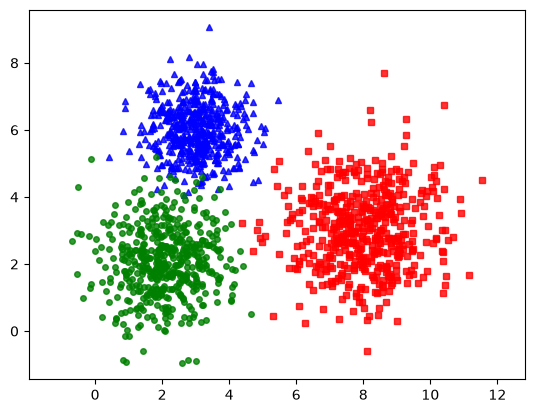

In [3]:
def kmeans_display(X, label):
    K = np.amax(label) + 1
    X0 = X[label == 0, :]
    X1 = X[label == 1, :]
    X2 = X[label == 2, :]
    plt.plot(X0[:, 0], X0[:, 1], 'b^', markersize = 4, alpha = .8)
    plt.plot(X1[:, 0], X1[:, 1], 'go', markersize = 4, alpha = .8)
    plt.plot(X2[:, 0], X2[:, 1], 'rs', markersize = 4, alpha = .8)

    plt.axis('equal')
    plt.plot()
    plt.show()
kmeans_display(X, y)

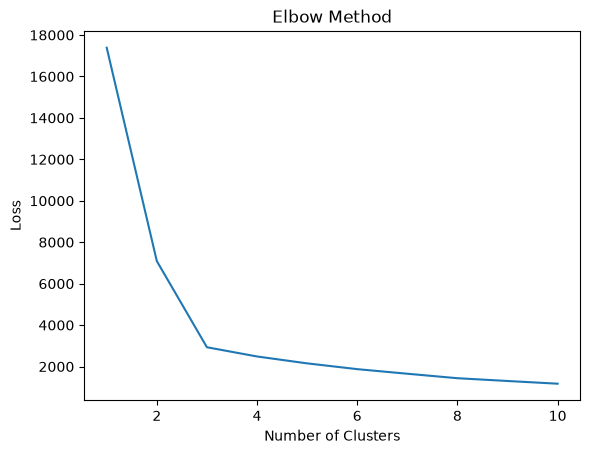

Centers found by our algorithm:  [[2.99527748 5.97736696]
 [2.09168267 2.01386306]
 [8.04281438 3.02544889]]
Loss:  2930.8570050778035


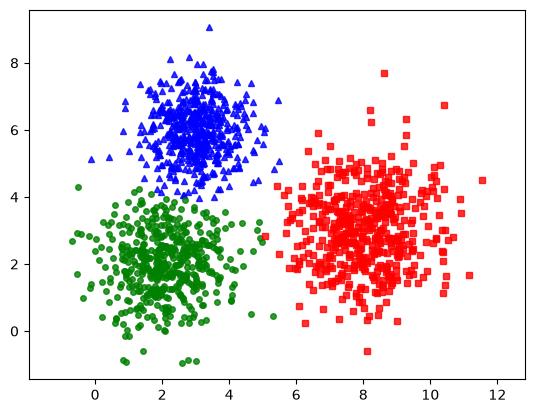

In [4]:

def kmeans_init_centers(X, k):
    indices = np.random.choice(X.shape[0], size = k, replace=False)
    return X[indices]
def kmeans_assign_labels(X, centers):
    D = cdist(X, centers)
    return np.argmin(D, axis=1)
def kmeans_update_centers(X, labels, k):
    centers = np.zeros((k, X.shape[1]))
    for i in range(k):
        Xk = X[labels == i, :]
        centers[i, :] = np.mean(Xk, axis=0)
    return centers
def has_converged(centers, new_centers):
    return (set([tuple(a) for a in centers]) == set([tuple(a) for a in new_centers]))
def kmeans(X, k):
    centers = [kmeans_init_centers(X, k)]
    labels = []
    it = 0
    while True:
        labels.append(kmeans_assign_labels(X, centers[-1]))
        new_centers = kmeans_update_centers(X, labels[-1], k)
        if(has_converged(centers[-1], new_centers)):
            break
        centers.append(new_centers)
        it += 1
    return (centers, labels, it)
def loss(X, centers, labels):
    return np.sum((X - centers[labels]) ** 2)
def multiple_kmeans(X, k, n):
    best_loss = np.inf
    best_centers = None
    best_labels = None
    for i in range(n):
        centers, labels, it = kmeans(X, k)
        current_loss = loss(X, centers[-1], labels[-1])
        if current_loss < best_loss:
            best_loss = current_loss
            best_centers = centers[-1]
            best_labels = labels[-1]
    return (best_centers, best_labels, best_loss)
def elbow(X, k, n):
    Lossess = []
    for i in range(1, k + 1):
        centers, labels, best_loss = multiple_kmeans(X, i, n)
        Lossess.append(best_loss)
    plt.plot(range(1, k + 1), Lossess)
    plt.xlabel('Number of Clusters')
    plt.ylabel('Loss')
    plt.title('Elbow Method')
    plt.show()
elbow(X, 10, 1000)
centers, labels, best_loss = multiple_kmeans(X, k, 1000)
print("Centers found by our algorithm: ", centers)
print("Loss: ", best_loss)
kmeans_display(X, labels)

Centers found by scikit-learn:
[[8.04817525 3.02281392]
 [2.09168267 2.01386306]
 [2.99995066 5.97416081]]
Loss:  2930.873685949054


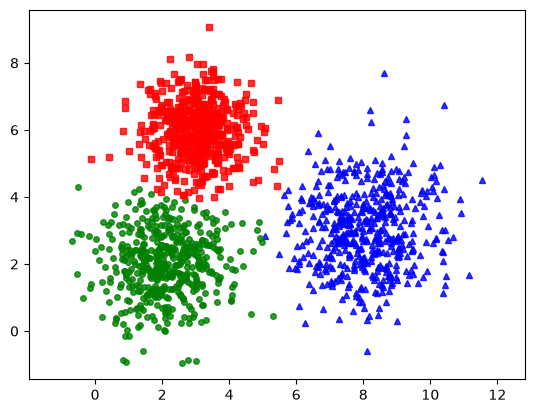

In [5]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=k).fit(X)
print('Centers found by scikit-learn:')
print(kmeans.cluster_centers_)
pred_label = kmeans.predict(X)
print("Loss: ", loss(X, kmeans.cluster_centers_, pred_label))
kmeans_display(X, pred_label)

In [6]:
print("My loss: ", best_loss)
print("SKlearn loss: ", loss(X, kmeans.cluster_centers_, pred_label))

My loss:  2930.8570050778035
SKlearn loss:  2930.873685949054
